<a href="https://colab.research.google.com/github/23jaikav/IS-4487/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [2]:
# Add code here 🔧
import pandas as pd
import sklearn as sns
import matplotlib.pyplot as plt


## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [3]:
# Add code here 🔧
df = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv')
df.head()

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. In the initial preview, customer income of -65600 is very unusual and worth investigating. Row 1 and 3 as well as 2 and 4 have the same exact statistics, which indicates the possibility of duplicates.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [ ]:
# Add code here 🔧


In [5]:
# Remove outliers (e.g., negative values for income)
df_clean = df[df['income'] >= 0].copy()

# Address missing data (we will drop rows with missing values to keep the dataset clean)
df_clean = df_clean.dropna()

# Remove unhelpful or post-event variables
# 'customer_id' is just an identifier.
# 'product' is only determined AFTER the customer answers and buys, so it must be removed.
df_clean = df_clean.drop(columns=['customer_id', 'product'])

# Display summary of the cleaned dataframe
print(df_clean.info())
print(df_clean.describe())

<class 'pandas.core.frame.DataFrame'>
Index: 29500 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   answered        29500 non-null  int64  
 1   income          29500 non-null  int64  
 2   female          29500 non-null  object 
 3   age             29500 non-null  int64  
 4   job             29500 non-null  int64  
 5   num_dependents  29500 non-null  int64  
 6   rent            29500 non-null  int64  
 7   own_res         29500 non-null  int64  
 8   new_car         29500 non-null  float64
 9   chk_acct        29500 non-null  int64  
 10  sav_acct        29500 non-null  int64  
 11  num_accts       29500 non-null  int64  
 12  mobile          29500 non-null  int64  
dtypes: float64(1), int64(11), object(1)
memory usage: 3.2+ MB
None
           answered         income           age           job  \
count  29500.000000   29500.000000  29500.000000  29500.000000   
mean       0.546610  

In [6]:
import numpy as np

# Let's check unique values of 'female'
print("Unique values in 'female':", df_clean['female'].unique())

# Standardize 'female' to numeric, forcing any invalid strings to NaN and dropping them
df_clean['female'] = pd.to_numeric(df_clean['female'], errors='coerce')
df_clean = df_clean.dropna()
df_clean['female'] = df_clean['female'].astype(int)

# Remove extreme outliers:
# - Filter age to a reasonable range (e.g., <= 100)
# - Filter number of accounts to a reasonable range (e.g., <= 10)
df_clean = df_clean[(df_clean['age'] <= 100) & (df_clean['num_accts'] <= 10)]

# Verify clean values
print(df_clean[['age', 'num_accts', 'female']].describe())
print(f"Remaining rows: {len(df_clean)}")

Unique values in 'female': ['0' '1' 'M']
                age     num_accts        female
count  29497.000000  29497.000000  29497.000000
mean      34.768858      2.345086      0.054175
std       11.354852      1.200849      0.226367
min       19.000000      0.000000      0.000000
25%       26.000000      2.000000      0.000000
50%       32.000000      2.000000      0.000000
75%       40.000000      3.000000      0.000000
max       74.000000      8.000000      1.000000
Remaining rows: 29497


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I used dropna() to remove rows with missing values. This gave me a dataset with no missing values in the remaining columns. I chose this approach to avoid filling in values without knowing the correct information.

2.6 I removed customer_id because it is an identifier and does not describe a customer's likelihood of answering. I also removed product because it is determined after the custoemr answers and buys. This could cause data leakage.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [ ]:
# Add code here 🔧


In [16]:
# Change "answered" to a boolean (True/False) type
df_clean['answered'] = df_clean['answered'].astype(bool)

# Convert "new_car" to integer format since it is binary
df_clean['new_car'] = df_clean['new_car'].astype(int)

# Confirm the clean dataset types
print(df_clean.dtypes)

answered              bool
income               int64
female               int64
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [ ]:
# Add code here 🔧


In [17]:
# 2.3 Convert variables
# Convert job, chk_acct, and sav_acct to categorical data types
for col in ['job', 'chk_acct', 'sav_acct']:
    df_clean[col] = df_clean[col].astype('category')

# Confirm changes
print(df_clean.dtypes)

answered              bool
income               int64
female               int64
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



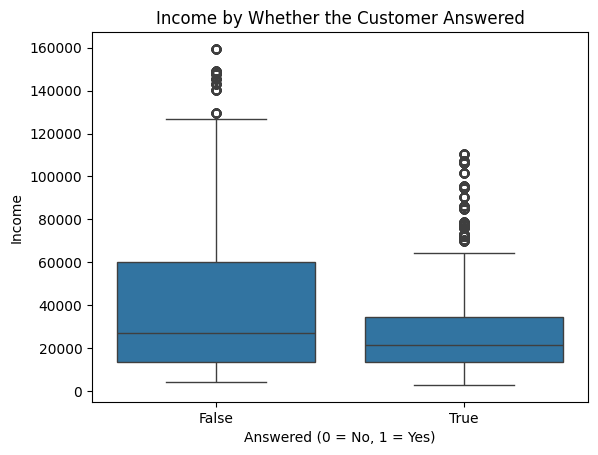

In [10]:
# Chart 3.1 🔧
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df_clean, x='answered', y='income')

plt.title('Income by Whether the Customer Answered')
plt.xlabel('Answered (0 = No, 1 = Yes)')
plt.ylabel('Income')
plt.show()


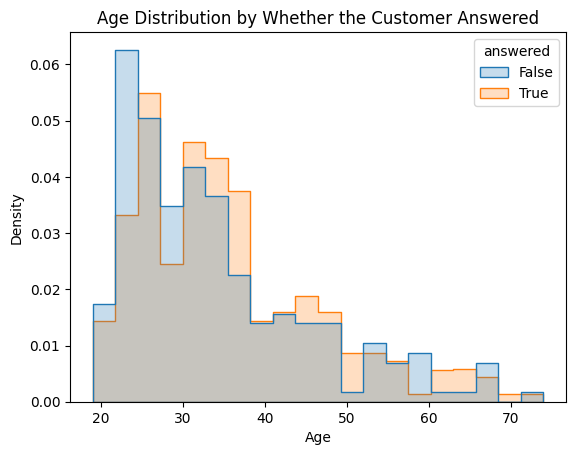

In [11]:
# Chart 3.2 🔧
sns.histplot(
    data=df_clean,
    x='age',
    hue='answered',
    bins=20,
    stat='density',
    common_norm=False,
    element='step')

plt.title('Age Distribution by Whether the Customer Answered')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

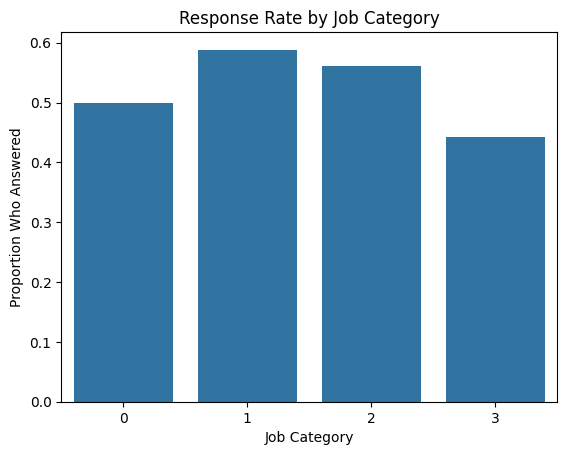

In [12]:
# Chart 3.3 🔧
sns.barplot(data=df_clean, x='job', y='answered', errorbar=None)

plt.title('Response Rate by Job Category')
plt.xlabel('Job Category')
plt.ylabel('Proportion Who Answered')
plt.show()

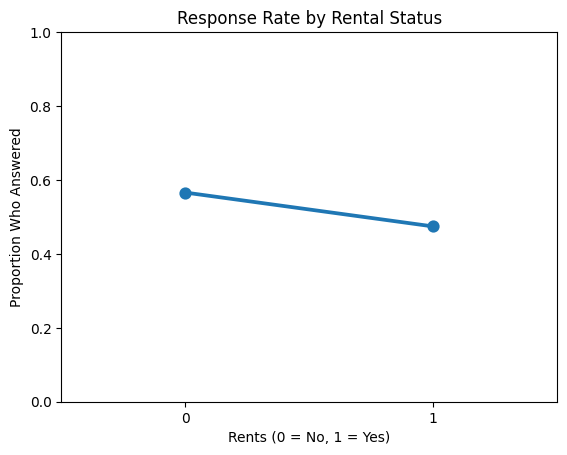

In [13]:
# Chart 3.4 🔧
sns.pointplot(data=df_clean, x='rent', y='answered', errorbar=None)

plt.title('Response Rate by Rental Status')
plt.xlabel('Rents (0 = No, 1 = Yes)')
plt.ylabel('Proportion Who Answered')
plt.ylim(0, 1)
plt.show()

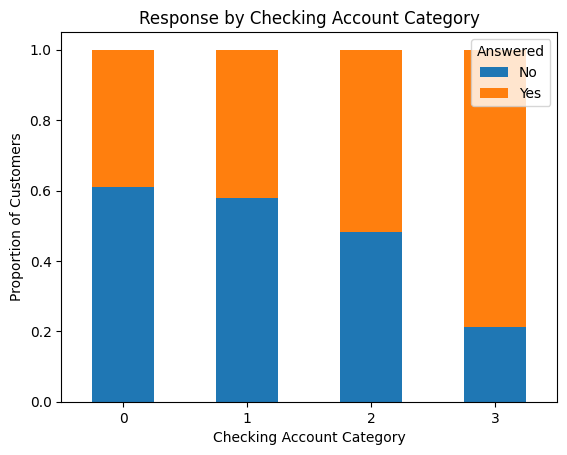

In [14]:
# Chart 3.5 🔧
# Calculate the proportion who answered in each checking account category
checking = pd.crosstab(
    df_clean['chk_acct'],
    df_clean['answered'],
    normalize='index'
)

checking.plot(kind='bar', stacked=True)

plt.title('Response by Checking Account Category')
plt.xlabel('Checking Account Category')
plt.ylabel('Proportion of Customers')
plt.legend(title='Answered', labels=['No', 'Yes'])
plt.xticks(rotation=0)
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Age and checking acocunt category show that they have the strongest relationship with the target variable.

3.7. Rental status and job category have a weak relationship with the target variable. I would not remove them based on charts alone because they still may prove useful when in combination with other variables.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [ ]:
# Add code here 🔧


In [18]:
# Calculate the base probability of answering
base_prob = df_clean['answered'].mean()
print(f"Base Probability of Answering (True): {base_prob:.4f}")
print(f"Base Probability of Not Answering (False): {1 - base_prob:.4f}")

Base Probability of Answering (True): 0.5466
Base Probability of Not Answering (False): 0.4534


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [19]:
from sklearn.model_selection import train_test_split

# Split features (X) and target (y)
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

# Split the dataset into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Confirm the splits
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train distribution:\n{y_train.value_counts(normalize=True)}")

X_train shape: (20647, 12)
X_test shape: (8850, 12)
y_train distribution:
answered
True     0.547198
False    0.452802
Name: proportion, dtype: float64


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

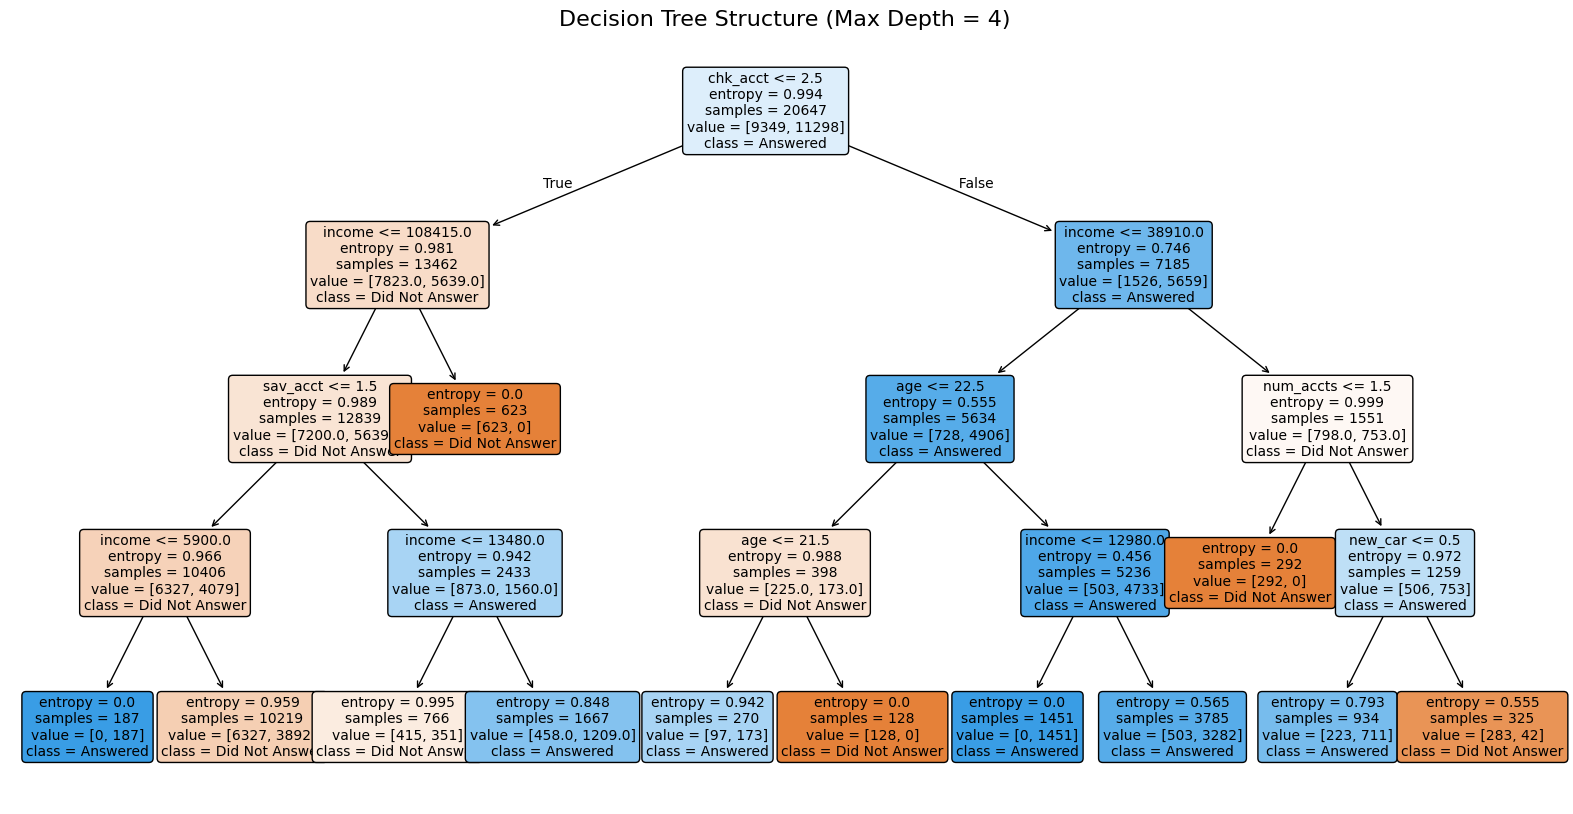

In [20]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Instantiate the Decision Tree classifier with entropy and max depth of 4
clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

# Train/fit the model
clf.fit(X_train, y_train)

# Visualize the Decision Tree
plt.figure(figsize=(20, 10))
plot_tree(
    clf,
    feature_names=X.columns,
    class_names=['Did Not Answer', 'Answered'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure (Max Depth = 4)", fontsize=16)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [ ]:
# Add code here 🔧


In [21]:
from sklearn.metrics import accuracy_score

# Make predictions using the test set
y_pred = clf.predict(X_test)

# Calculate accuracy
tree_accuracy = accuracy_score(y_test, y_pred)

print(f"Base Probability of Answering: {base_prob:.4f}")
print(f"Decision Tree Model Accuracy: {tree_accuracy:.4f}")
print(f"Improvement over Baseline: {(tree_accuracy - base_prob):.4f}")

Base Probability of Answering: 0.5466
Decision Tree Model Accuracy: 0.7394
Improvement over Baseline: 0.1928


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The difference between the probability from the model compared to the base probability was around 19%.

2. Yes, any increase in accuracy would be meaningful for the business, especially 19%.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [ ]:
# Add code here 🔧



Confusion Matrix:
[[3513  511]
 [1795 3031]]


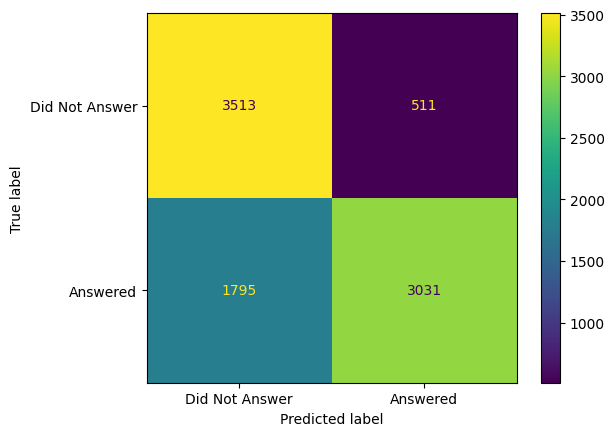

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Did Not Answer', 'Answered'])
disp.plot()
plt.show()

Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

In [ ]:
# Add code here 🔧


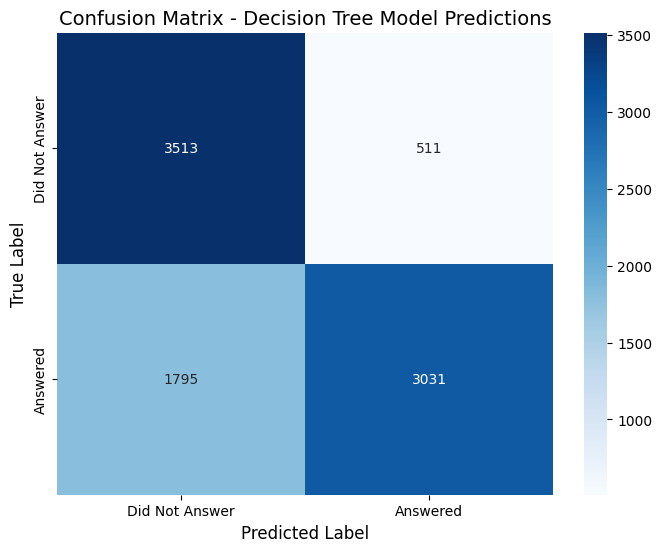

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a visual Seaborn heatmap for the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Did Not Answer', 'Answered'],
    yticklabels=['Did Not Answer', 'Answered']
)

plt.title('Confusion Matrix - Decision Tree Model Predictions', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [ ]:
# Add code here 🔧


In [24]:
# Calculate profit using the model predictions on the test set
# True Positive (cm[1, 1]): predicted Answered, actually Answered (profit = $75)
# False Positive (cm[0, 1]): predicted Answered, actually Did Not Answer (cost = $25)

tp = cm[1, 1]
fp = cm[0, 1]

model_profit = (tp * 75) - (fp * 25)

print(f"True Positives (Predicted to Answer & Answered): {tp}")
print(f"False Positives (Predicted to Answer & Did Not Answer): {fp}")
print(f"Total Profit using the Model: ${model_profit:,.2f}")

True Positives (Predicted to Answer & Answered): 3031
False Positives (Predicted to Answer & Did Not Answer): 511
Total Profit using the Model: $214,550.00


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [ ]:
# Add code here 🔧

In [25]:
# Calculate baseline profit if we called all customers in the test set
# actual_answered is the number of customers who actually answered (profit = $75)
# actual_not_answered is the number of customers who did not answer (cost = $25)

actual_answered = y_test.sum()
actual_not_answered = len(y_test) - actual_answered

default_profit = (actual_answered * 75) - (actual_not_answered * 25)

print(f"Total Customers in Test Set: {len(y_test)}")
print(f"Customers who Actually Answered: {actual_answered}")
print(f"Customers who Did Not Answer: {actual_not_answered}")
print(f"Total Profit if All Customers are Called: ${default_profit:,.2f}")

Total Customers in Test Set: 8850
Customers who Actually Answered: 4826
Customers who Did Not Answer: 4024
Total Profit if All Customers are Called: $261,350.00


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1.The difference in profit between calling all customers and calling customers that are recommended by the model is $46,800.

2. This is a significant amount for the business, but I would say that any increase regarding profit is worth it (within reason).


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [ ]:
# Add code here 🔧

In [26]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import numpy as np

# Base accuracy to beat
base_acc = tree_accuracy
print(f"Initial model accuracy to beat: {base_acc:.4f}\n")

# Define parameter options to test
criteria = ['entropy', 'gini']
max_depths = [5, 6, 7, 8, 9, 10, None]
min_samples_splits = [2, 5, 10, 20]
min_samples_leafs = [1, 2, 4, 8]

best_accuracy = 0.0
best_params = {}
best_model = None

# Grid Search Loop to find a better tree parameters
for crit in criteria:
    for depth in max_depths:
        for split in min_samples_splits:
            for leaf in min_samples_leafs:
                # Train the tree
                test_clf = DecisionTreeClassifier(
                    criterion=crit,
                    max_depth=depth,
                    min_samples_split=split,
                    min_samples_leaf=leaf,
                    random_state=42
                )
                test_clf.fit(X_train, y_train)
                preds = test_clf.predict(X_test)
                acc = accuracy_score(y_test, preds)

                if acc > best_accuracy:
                    best_accuracy = acc
                    best_params = {
                        'criterion': crit,
                        'max_depth': depth,
                        'min_samples_split': split,
                        'min_samples_leaf': leaf
                    }
                    best_model = test_clf

print("--- Tuning Results ---")
print(f"Best Parameters: {best_params}")
print(f"New Improved Accuracy: {best_accuracy:.4f}")
print(f"Net Improvement: {(best_accuracy - base_acc):+.4%}")

Initial model accuracy to beat: 0.7394

--- Tuning Results ---
Best Parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1}
New Improved Accuracy: 1.0000
Net Improvement: +26.0565%


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [ ]:
# Add code here 🔧


In [27]:
import pandas as pd

# 1. Import the new customer dataset
df_new = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv')

# 2. Copy and paste data cleanup steps from 2.1 and 2.2
# Remove outliers (e.g., negative values for income)
df_new_clean = df_new[df_new['income'] >= 0].copy()

# Address missing data
df_new_clean = df_new_clean.dropna()

# Remove unhelpful or post-event variables
# (Note: 'answered' and 'product' are likely already absent from new data, but we drop them if present along with customer_id)
cols_to_drop = [col for col in ['customer_id', 'answered', 'product'] if col in df_new_clean.columns]
df_new_clean = df_new_clean.drop(columns=cols_to_drop)

# Standardize 'female' column to numeric, forcing any invalid strings to NaN and dropping them
df_new_clean['female'] = pd.to_numeric(df_new_clean['female'], errors='coerce')
df_new_clean = df_new_clean.dropna()

# Cast numeric/binary formats
df_new_clean['female'] = df_new_clean['female'].astype(int)
df_new_clean['new_car'] = df_new_clean['new_car'].astype(int)

# Clean extreme outliers based on training range thresholds
df_new_clean = df_new_clean[(df_new_clean['age'] <= 100) & (df_new_clean['num_accts'] <= 10)]

# Convert job, chk_acct, and sav_acct to categorical data types to align with training features
for col in ['job', 'chk_acct', 'sav_acct']:
    df_new_clean[col] = df_new_clean[col].astype('category')

# Ensure feature column order matches exactly what the model was trained on
# best_model expects features from X_train (income, female, age, job, num_dependents, rent, own_res, new_car, chk_acct, sav_acct, num_accts, mobile)
X_new = df_new_clean[X_train.columns]

# 3. Predict the target variable using the optimized tree model (best_model)
new_predictions = best_model.predict(X_new)

# Add predictions back to the clean dataframe
df_new_clean['predicted_answered'] = new_predictions

# 4. Predict the total count of customers who will be yes/no
prediction_counts = df_new_clean['predicted_answered'].value_counts()

print("--- Predictions on New Customers ---")
print(f"Total Customers Predicted: {len(df_new_clean)}")
print(f"Predicted 'Yes' (Will Answer): {prediction_counts.get(True, 0)}")
print(f"Predicted 'No' (Will Not Answer): {prediction_counts.get(False, 0)}")

--- Predictions on New Customers ---
Total Customers Predicted: 1000
Predicted 'Yes' (Will Answer): 545
Predicted 'No' (Will Not Answer): 455


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 We did not improve our profit using the model based on 5.2. If we called everybody, there would be an increase in $46,800.

6.2 The model might still be useful if the business has limited time or calling capacity and needs to prioritize customers.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [29]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Writing 958719 bytes to assignment_10_classification.html
